<a href="https://colab.research.google.com/github/jun-yuaka/deep-learning-llm-notes/blob/main/deep_learning_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import numpy as np

num_samples_per_class = 1000
negative_samples = np.random.multivariate_normal(
    mean=[0, 3], cov=[[1, 0.5], [0.5, 1]], size=num_samples_per_class
)
positive_samples = np.random.multivariate_normal(
    mean=[3, 0], cov=[[1, 0.5], [0.5, 1]], size=num_samples_per_class
)

In [4]:
inputs = np.vstack((negative_samples, positive_samples)).astype(np.float32)

In [5]:
targets = np.vstack(
    (
        np.zeros((num_samples_per_class, 1), dtype="float32"),
        np.ones((num_samples_per_class, 1), dtype="float32"),
    )
)

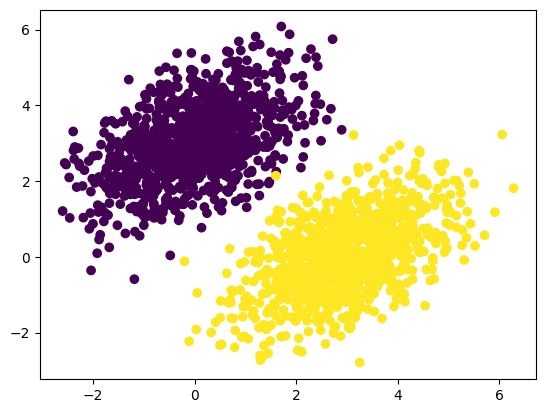

In [6]:
import matplotlib.pyplot as plt

plt.scatter(inputs[:, 0], inputs[:, 1], c=targets[:, 0])
plt.show()

In [8]:
import tensorflow as tf

input_dim = 2
output_dim = 1
W = tf.Variable(
    initial_value=tf.random.uniform(shape=(input_dim, output_dim))
)
b = tf.Variable(
    initial_value=tf.zeros(shape=(output_dim,))
)

In [9]:
def model(inputs, W, b):
  return tf.matmul(inputs, W) + b

In [13]:
def mean_squared_error(targets, predictions):
  per_sample_losses = tf.square(targets - predictions)
  return tf.reduce_mean(per_sample_losses)

In [14]:
learning_rate = 0.1

@tf.function(jit_compile=True)
def training_step(inputs, targets, W, b):
  with tf.GradientTape() as tape:
    predictions = model(inputs, W, b)
    loss = mean_squared_error(predictions, targets)
  grad_loss_wrt_W, grad_loss_wrt_b = tape.gradient(loss, [W, b])
  W.assign_sub(grad_loss_wrt_W * learning_rate)
  b.assign_sub(grad_loss_wrt_b * learning_rate)
  return loss

In [15]:
for step in range(40):
  loss = training_step(inputs, targets, W, b)
  print(f"Loss at step {step}: {loss:.4f}")

Loss at step 0: 5.0484
Loss at step 1: 0.8417
Loss at step 2: 0.2514
Loss at step 3: 0.1600
Loss at step 4: 0.1383
Loss at step 5: 0.1270
Loss at step 6: 0.1179
Loss at step 7: 0.1097
Loss at step 8: 0.1023
Loss at step 9: 0.0955
Loss at step 10: 0.0893
Loss at step 11: 0.0837
Loss at step 12: 0.0786
Loss at step 13: 0.0739
Loss at step 14: 0.0697
Loss at step 15: 0.0658
Loss at step 16: 0.0622
Loss at step 17: 0.0590
Loss at step 18: 0.0561
Loss at step 19: 0.0534
Loss at step 20: 0.0509
Loss at step 21: 0.0487
Loss at step 22: 0.0467
Loss at step 23: 0.0448
Loss at step 24: 0.0431
Loss at step 25: 0.0416
Loss at step 26: 0.0402
Loss at step 27: 0.0389
Loss at step 28: 0.0377
Loss at step 29: 0.0367
Loss at step 30: 0.0357
Loss at step 31: 0.0348
Loss at step 32: 0.0340
Loss at step 33: 0.0333
Loss at step 34: 0.0326
Loss at step 35: 0.0320
Loss at step 36: 0.0314
Loss at step 37: 0.0309
Loss at step 38: 0.0304
Loss at step 39: 0.0300


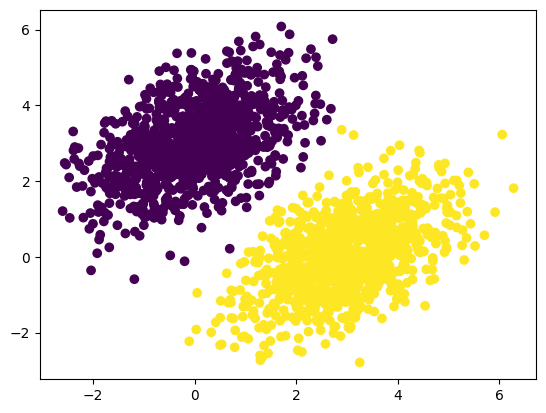

In [16]:
predictions = model(inputs=inputs, W=W, b=b)
plt.scatter(inputs[:, 0], inputs[:, 1], c=predictions[:, 0] > 0.5)
plt.show()

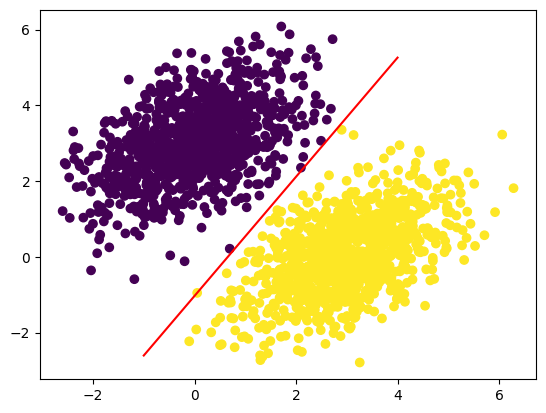

In [17]:
x = np.linspace(-1, 4, 100)
y = -W[0] / W[1] * x + (0.5 - b) / W[1]
plt.plot(x, y, "-r")
plt.scatter(inputs[:, 0], inputs[:, 1], c=predictions[:, 0] > 0.5)